# Online Shoppers Purchasing Intention – Machine Learning

This notebook follows the same general order as your previous notebook:
1. Load the dataset
2. Check and clean data
3. Detect and cap outliers
4. Encode categorical columns
5. Separate features (`X`) and target (`y`)
6. Check class imbalance and apply RandomOverSampler
7. Split the data
8. Train Logistic Regression and Random Forest
9. Evaluate the models
10. Cross-validation and GridSearchCV

**Dataset:** `online_shoppers_intention(3).csv`

Run the cells from top to bottom. If the CSV is not in the notebook's current folder, update the file path in the dataset-loading cell.


## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)
from imblearn.over_sampling import RandomOverSampler


## 2. Load the dataset

In [2]:
df = pd.read_csv(r"C:\Users\Dell\Desktop\Autonomous_Enterprise_Intelligence\data\online_shoppers_intention.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Inspect the dataset

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Column names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

Dataset information:
<class 'pandas.

## 4. Remove duplicate rows and check missing values

In [4]:
df = df.drop_duplicates()

# Display rows with missing values, if any
print("Missing values after duplicate removal:")
print(df.isnull().sum())

# This dataset normally has no missing values. If any are present,
# fill numeric columns with their median and categorical columns with their mode.
for column in df.columns:
    if df[column].isnull().any():
        if df[column].dtype == "object" or str(df[column].dtype) == "bool":
            df[column] = df[column].fillna(df[column].mode()[0])
        else:
            df[column] = df[column].fillna(df[column].median())

print("\nShape after cleaning:", df.shape)


Missing values after duplicate removal:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Shape after cleaning: (12205, 18)


## 5. Detect outliers using boxplots

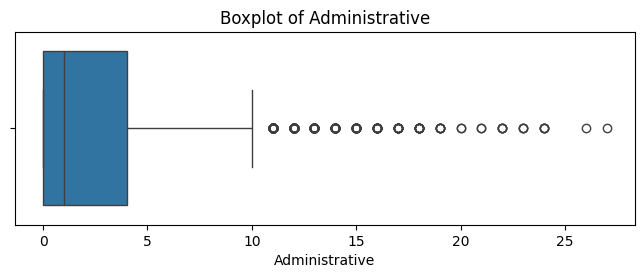

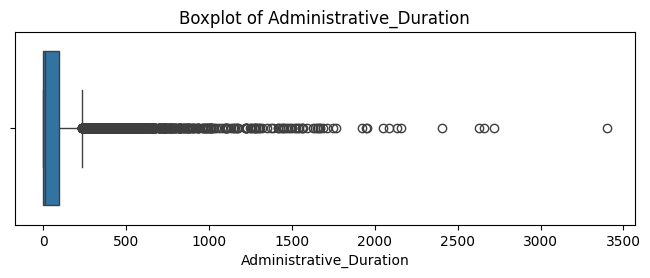

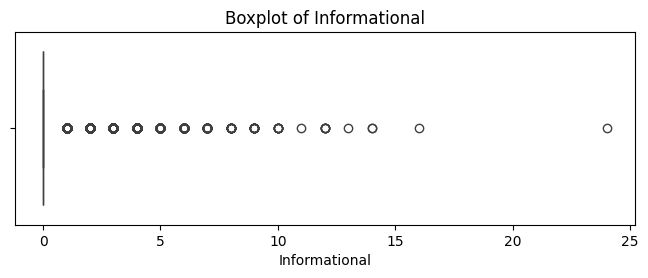

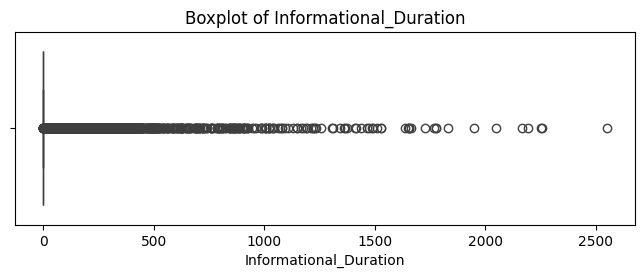

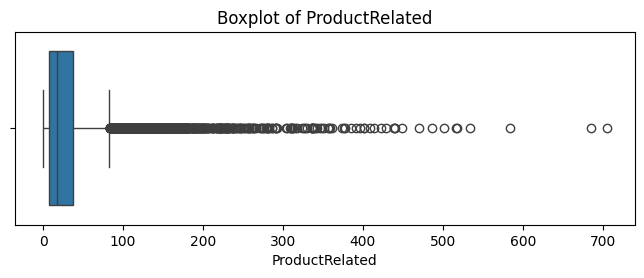

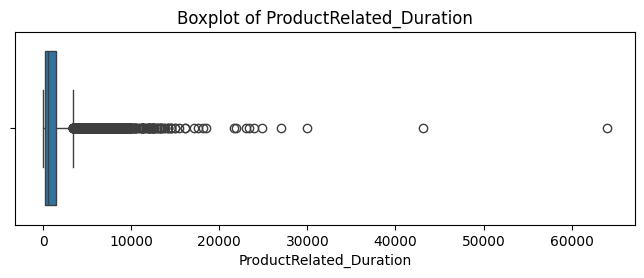

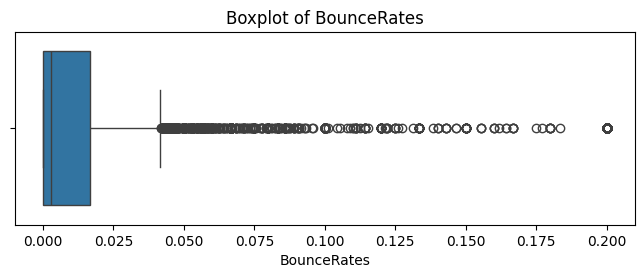

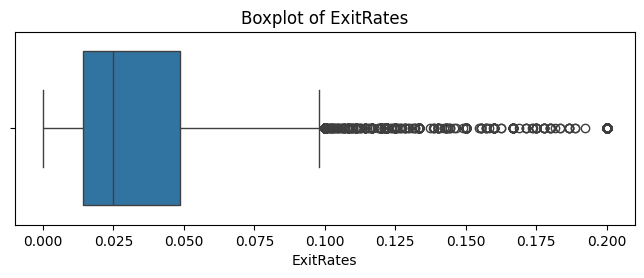

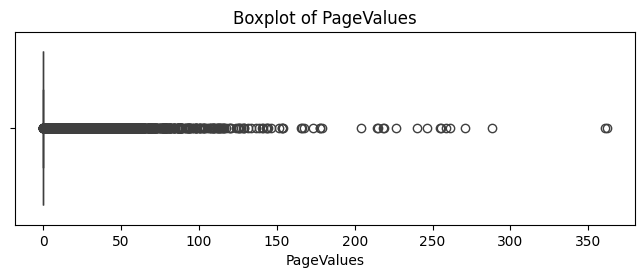

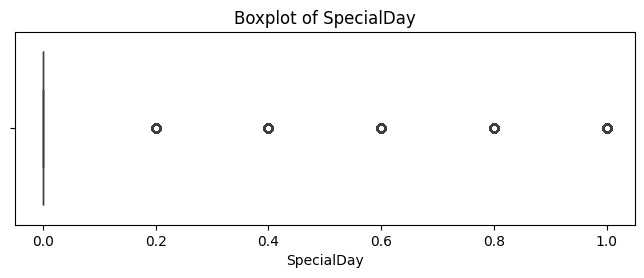

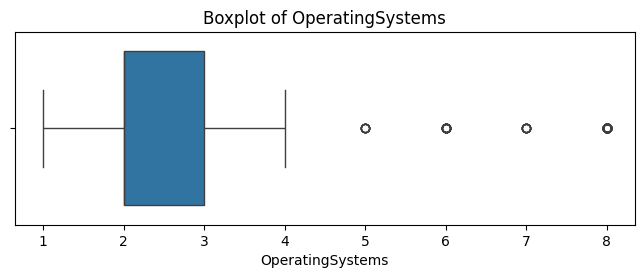

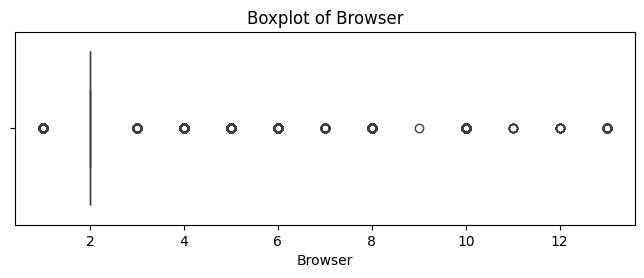

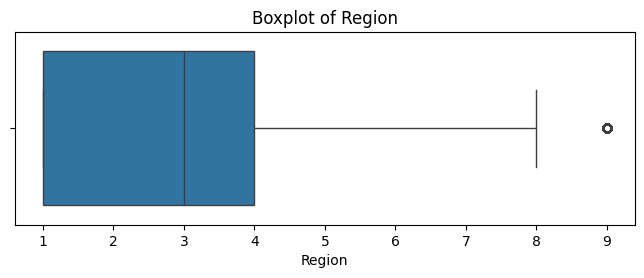

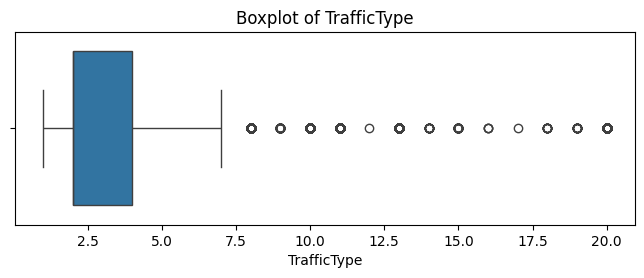

In [5]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

for column in numeric_columns:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.show()


## 6. Detect and cap outliers using the IQR method

In [6]:
# Cap numeric outliers at the IQR lower and upper limits.
# This keeps the rows instead of deleting them.
for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[column] = df[column].clip(lower=lower_limit, upper=upper_limit)

print("Outlier capping completed.")
display(df.head())


Outlier capping completed.


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.041667,0.099977,0.0,0.0,Feb,1.0,2,1.0,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.099977,0.0,0.0,Feb,2.0,2,1.0,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.041667,0.099977,0.0,0.0,Feb,4.0,2,8.5,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.041667,0.099977,0.0,0.0,Feb,3.0,2,2.0,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,Feb,3.0,2,1.0,4,Returning_Visitor,True,False


## 7. Encode the target and categorical columns

In [7]:
# Convert the Boolean target to 0 and 1.
df["Revenue"] = df["Revenue"].astype(int)

# Convert Boolean feature to integer.
df["Weekend"] = df["Weekend"].astype(int)

# One-hot encode categorical columns.
df_encoded = pd.get_dummies(
    df,
    columns=["Month", "VisitorType"],
    drop_first=True,
    dtype=int
)

print("Encoded dataset shape:", df_encoded.shape)
display(df_encoded.head())


Encoded dataset shape: (12205, 27)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Feb,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_Other,VisitorType_Returning_Visitor
0,0,0.0,0,0.0,1,0.000000,0.041667,0.099977,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1
1,0,0.0,0,0.0,2,64.000000,0.000000,0.099977,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1
2,0,0.0,0,0.0,1,0.000000,0.041667,0.099977,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1
3,0,0.0,0,0.0,2,2.666667,0.041667,0.099977,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1


## 8. Separate features (X) and target (y)

In [8]:
X = df_encoded.drop("Revenue", axis=1)
y = df_encoded["Revenue"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())


X shape: (12205, 26)
y shape: (12205,)

Target values:
Revenue
0    10297
1     1908
Name: count, dtype: int64


## 9. Check class imbalance

Revenue class counts:
Revenue
0    10297
1     1908
Name: count, dtype: int64

Revenue class percentages:
Revenue
0    84.37
1    15.63
Name: proportion, dtype: float64


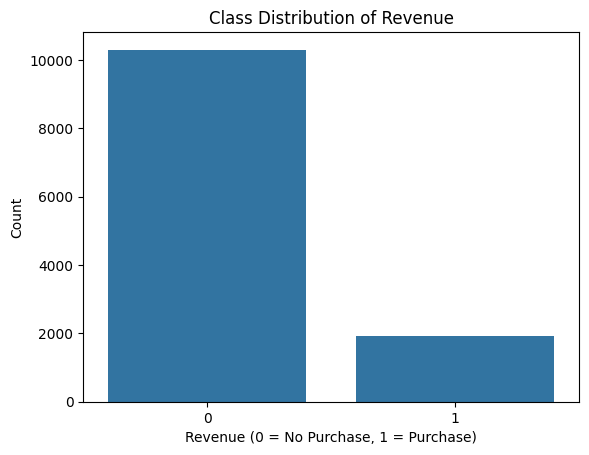

In [9]:
print("Revenue class counts:")
print(y.value_counts())

print("\nRevenue class percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

sns.countplot(x=y)
plt.title("Class Distribution of Revenue")
plt.xlabel("Revenue (0 = No Purchase, 1 = Purchase)")
plt.ylabel("Count")
plt.show()


## 10. Apply RandomOverSampler

This follows the oversampling-before-splitting order from your previous notebook. Be aware that oversampling before the train-test split can cause data leakage and overly optimistic evaluation scores. For a strictly reliable evaluation, oversampling should be applied only to training data; this notebook keeps the earlier order to match your requested workflow.


In [10]:
ros = RandomOverSampler(random_state=42)
X_ros, y_ros = ros.fit_resample(X, y)

print("Before oversampling:")
print(y.value_counts())

print("\nAfter oversampling:")
print(y_ros.value_counts())

print("\nOversampled X shape:", X_ros.shape)
print("Oversampled y shape:", y_ros.shape)


Before oversampling:
Revenue
0    10297
1     1908
Name: count, dtype: int64

After oversampling:
Revenue
0    10297
1    10297
Name: count, dtype: int64

Oversampled X shape: (20594, 26)
Oversampled y shape: (20594,)


## 11. Split the data into training and testing sets

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X_ros,
    y_ros,
    test_size=0.2,
    random_state=42,
    stratify=y_ros
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (16475, 26)
X_test: (4119, 26)
y_train: (16475,)
y_test: (4119,)


## 12. Logistic Regression

In [12]:
# Scale the features for Logistic Regression.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_predictions))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_predictions))
print("\nClassification Report:")
print(classification_report(y_test, lr_predictions, zero_division=0))
print("Precision:", precision_score(y_test, lr_predictions, zero_division=0))
print("Recall:", recall_score(y_test, lr_predictions, zero_division=0))


Logistic Regression Accuracy: 0.6751638747268754

Confusion Matrix:
[[1294  766]
 [ 572 1487]]

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.63      0.66      2060
           1       0.66      0.72      0.69      2059

    accuracy                           0.68      4119
   macro avg       0.68      0.68      0.67      4119
weighted avg       0.68      0.68      0.67      4119

Precision: 0.6600088770528184
Recall: 0.722195240407965


## 13. Random Forest

In [13]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_predictions))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))
print("\nClassification Report:")
print(classification_report(y_test, rf_predictions, zero_division=0))
print("Precision:", precision_score(y_test, rf_predictions, zero_division=0))
print("Recall:", recall_score(y_test, rf_predictions, zero_division=0))


Random Forest Accuracy: 0.9647972808934208

Confusion Matrix:
[[1926  134]
 [  11 2048]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.93      0.96      2060
           1       0.94      0.99      0.97      2059

    accuracy                           0.96      4119
   macro avg       0.97      0.96      0.96      4119
weighted avg       0.97      0.96      0.96      4119

Precision: 0.9385884509624198
Recall: 0.9946576007770762


## 14. Compare model results

In [14]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, lr_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, lr_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ]
})

display(results.sort_values(by="Accuracy", ascending=False))


,Model,Accuracy,Precision,Recall
1,Random Forest,0.964797,0.938588,0.994658
0,Logistic Regression,0.675164,0.660009,0.722195


## 15. Cross-validation

In [15]:
# Cross-validation is performed on the original encoded data.
# This is separate from the oversampled train/test evaluation above.
lr_cv_scores = cross_val_score(
    LogisticRegression(max_iter=1000, random_state=42),
    X,
    y,
    cv=5,
    scoring="accuracy"
)

rf_cv_scores = cross_val_score(
    RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("Logistic Regression CV scores:", lr_cv_scores)
print("Logistic Regression mean CV accuracy:", lr_cv_scores.mean())

print("\nRandom Forest CV scores:", rf_cv_scores)
print("Random Forest mean CV accuracy:", rf_cv_scores.mean())


c:\Users\Dell\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\Dell\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://sci

Logistic Regression CV scores: [0.84350676 0.84268742 0.83080705 0.84186809 0.84063908]
Logistic Regression mean CV accuracy: 0.8399016796394921

Random Forest CV scores: [0.8467841  0.83900041 0.83900041 0.84391643 0.8275297 ]
Random Forest mean CV accuracy: 0.8392462105694387


## 16. Hyperparameter tuning with GridSearchCV

In [16]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_ros, y_ros)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-validation Score:", grid_search.best_score_)

best_model = grid_search.best_estimator_
best_predictions = best_model.predict(X_test)

print("\nTuned Random Forest Accuracy:", accuracy_score(y_test, best_predictions))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, best_predictions))
print("\nClassification Report:")
print(classification_report(y_test, best_predictions, zero_division=0))


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best Cross-validation Score: 0.6965061916718872

Tuned Random Forest Accuracy: 0.9997572226268512

Confusion Matrix:
[[2059    1]
 [   0 2059]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2060
           1       1.00      1.00      1.00      2059

    accuracy                           1.00      4119
   macro avg       1.00      1.00      1.00      4119
weighted avg       1.00      1.00      1.00      4119



## 17. Final summary

In [17]:
print("Dataset rows after cleaning:", df.shape[0])
print("Number of input features:", X.shape[1])
print("Logistic Regression accuracy:", accuracy_score(y_test, lr_predictions))
print("Random Forest accuracy:", accuracy_score(y_test, rf_predictions))
print("Tuned Random Forest accuracy:", accuracy_score(y_test, best_predictions))


Dataset rows after cleaning: 12205
Number of input features: 26
Logistic Regression accuracy: 0.6751638747268754
Random Forest accuracy: 0.9647972808934208
Tuned Random Forest accuracy: 0.9997572226268512


# 18. RAG Implementation for Online Shoppers

This section follows the structure of the uploaded RAG implementation notebook: load the project knowledge document, split it into chunks, create embeddings, build a FAISS vector database, create a retriever, define a prompt template, and build a RAG chain.

**Required file:** `Online_Shoppers_Dataset_Knowledge_Base_5_Pages.pdf`. Update the path if your PDF is stored somewhere else.


## 18.1 Install packages

In [18]:
# Run this cell if the required packages are not installed.
%pip install -q langchain langchain-groq langchain-core langchain-community langchain-text-splitters langchain-huggingface sentence-transformers faiss-cpu pypdf langgraph


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 18.2 Set API key securely

In [2]:

import os
from getpass import getpass

api_key = getpass("Enter your NEW Groq API key: ")

if api_key.strip():
    os.environ["GROQ_API_KEY"] = api_key.strip()
    print("Groq API key configured successfully.")
else:
    print("API key empty. Please run the cell again.")


Groq API key configured successfully.


## 18.3 Build the LLM model

In [3]:

import os
from langchain_groq import ChatGroq

llm_model = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0.2,
    api_key=os.environ["GROQ_API_KEY"]
)

response = llm_model.invoke(
    "What is the Online Shoppers Purchasing Intention dataset?"
)

print(response.content)


c:\Users\Dell\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Online Shoppers Purchasing Intention (OSPI) Dataset – Quick Overview**

| Item | Description |
|------|-------------|
| **Source** | UCI Machine Learning Repository – *Online Shoppers Purchasing Intention Dataset* (originally collected by the University of California, Irvine, 2015). |
| **Link** | https://archive.ics.uci.edu/ml/datasets/Online+Shoppers+Purchasing+Intention+Dataset |
| **Domain** | E‑commerce / Web analytics – predicting whether a visitor will complete a purchase (i.e., generate revenue) during a browsing session. |
| **Task** | Binary classification (Revenue = **TRUE** / **FALSE**). Often used to benchmark classification algorithms, feature‑selection methods, and cost‑sensitive learning. |
| **Size** | 12 330 instances (sessions) × 18 attributes (including the target). |
| **File format** | CSV (comma‑separated) with a header row. No missing values. |
| **Typical use‑case** | Build a model that can flag “high‑intent” sessions in real time so that a retailer can trigg

## 18.4 Load the knowledge document

In [4]:

from pathlib import Path
from tkinter import Tk, filedialog

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

pdf_file = filedialog.askopenfilename(
    title="Select your RAG knowledge PDF",
    filetypes=[("PDF files", "*.pdf")]
)

root.destroy()

if pdf_file:
    PDF_PATH = Path(pdf_file)
    print("PDF selected:", PDF_PATH)
else:
    print("PDF select cheyyaledu.")


PDF selected: C:\Users\Dell\Desktop\Autonomous_Enterprise_Intelligence\documents\Online_Shoppers_Dataset_Knowledge_Base_5_Pages.pdf


In [7]:

from pathlib import Path
from pypdf import PdfReader

print("PDF path:", PDF_PATH)
print("File exists:", PDF_PATH.exists())

reader = PdfReader(str(PDF_PATH))
print("Pages loaded:", len(reader.pages))

print(reader.pages[0].extract_text()[:1000])


PDF path: C:\Users\Dell\Desktop\Autonomous_Enterprise_Intelligence\documents\Online_Shoppers_Dataset_Knowledge_Base_5_Pages.pdf
File exists: True
Pages loaded: 5
Page 1 of 5
 ONLINE SHOPPERS PURCHASING INTENTION
Dataset Knowledge Base for RAG and Streamlit
Purpose of this document
This knowledge base explains the Online Shoppers Purchasing Intention dataset. It focuses on the dataset, its columns, the
meaning of recorded session information, and common questions a user may ask through a dataset chatbot. It is not a
general machine-learning textbook.
1. Dataset overview
 Dataset name: Online Shoppers Purchasing Intention Dataset.
 What one row represents: One browsing session on an online shopping website.
 What the dataset describes: Page visits, time spent on page categories, technical/session attributes, and whether a purchase
occurred.
 Target column: Revenue. In the original dataset, True means the session resulted in a purchase; False means it did not.
 Original dataset size:

In [9]:

from pathlib import Path
from langchain_community.document_loaders import PyPDFLoader

PDF_PATH = Path(
    r"C:\Users\Dell\Desktop\Autonomous_Enterprise_Intelligence\documents\Online_Shoppers_Dataset_Knowledge_Base_5_Pages.pdf"
)

print("PDF exists:", PDF_PATH.exists())

loader = PyPDFLoader(str(PDF_PATH))
document = loader.load()

print("Pages loaded:", len(document))
print(document[0].page_content[:1000])


PDF exists: True
Pages loaded: 5
Page 1 of 5
 ONLINE SHOPPERS PURCHASING INTENTION
Dataset Knowledge Base for RAG and Streamlit
Purpose of this document
This knowledge base explains the Online Shoppers Purchasing Intention dataset. It focuses on the dataset, its columns, the
meaning of recorded session information, and common questions a user may ask through a dataset chatbot. It is not a
general machine-learning textbook.
1. Dataset overview
 Dataset name: Online Shoppers Purchasing Intention Dataset.
 What one row represents: One browsing session on an online shopping website.
 What the dataset describes: Page visits, time spent on page categories, technical/session attributes, and whether a purchase
occurred.
 Target column: Revenue. In the original dataset, True means the session resulted in a purchase; False means it did not.
 Original dataset size: 12,330 sessions and 18 columns.
 Local project file: The previously cleaned project CSV contained 12,205 rows after cleaning. T

In [11]:

from pathlib import Path
from langchain_community.document_loaders import PyPDFLoader

PDF_PATH = Path(
    r"C:\Users\Dell\Desktop\Autonomous_Enterprise_Intelligence\documents\Online_Shoppers_Dataset_Knowledge_Base_5_Pages.pdf"
)

print("PDF exists:", PDF_PATH.exists())

if PDF_PATH.exists():
    loader = PyPDFLoader(str(PDF_PATH))
    document = loader.load()

    print("Pages loaded:", len(document))
    print(document[0].page_content[:1000])
else:
    print("PDF path incorrect. Check the file location.")


PDF exists: True
Pages loaded: 5
Page 1 of 5
 ONLINE SHOPPERS PURCHASING INTENTION
Dataset Knowledge Base for RAG and Streamlit
Purpose of this document
This knowledge base explains the Online Shoppers Purchasing Intention dataset. It focuses on the dataset, its columns, the
meaning of recorded session information, and common questions a user may ask through a dataset chatbot. It is not a
general machine-learning textbook.
1. Dataset overview
 Dataset name: Online Shoppers Purchasing Intention Dataset.
 What one row represents: One browsing session on an online shopping website.
 What the dataset describes: Page visits, time spent on page categories, technical/session attributes, and whether a purchase
occurred.
 Target column: Revenue. In the original dataset, True means the session resulted in a purchase; False means it did not.
 Original dataset size: 12,330 sessions and 18 columns.
 Local project file: The previously cleaned project CSV contained 12,205 rows after cleaning. T

## 18.5 Split the document into text chunks

In [12]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

rec_text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50
)

rec_chunks = rec_text_splitter.split_documents(document)

print("Total chunks:", len(rec_chunks))
print(rec_chunks[0].page_content)


Total chunks: 16
Page 1 of 5
 ONLINE SHOPPERS PURCHASING INTENTION
Dataset Knowledge Base for RAG and Streamlit
Purpose of this document
This knowledge base explains the Online Shoppers Purchasing Intention dataset. It focuses on the dataset, its columns, the
meaning of recorded session information, and common questions a user may ask through a dataset chatbot. It is not a
general machine-learning textbook.
1. Dataset overview
 Dataset name: Online Shoppers Purchasing Intention Dataset.


## 18.6 Create the vector database

In [13]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

embedding_model = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

vectorstore = FAISS.from_documents(
    rec_chunks,
    embedding_model
)

vectorstore


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 505.52it/s]


## 18.7 Create the retriever

In [14]:
retriever = vectorstore.as_retriever(
    search_kwargs={"k": 3}
)

retriever


VectorStoreRetriever(tags=['FAISS', 'HuggingFaceEmbeddings'], vectorstore=<langchain_community.vectorstores.faiss.FAISS object at 0x0000022D32C32990>, search_kwargs={'k': 3})

## 18.8 Create the chat prompt template

In [15]:
from langchain_core.prompts import ChatPromptTemplate

template = """
You are a helpful assistant for the Online Shoppers Purchasing Intention project.
Use the retrieved context to answer the user's question.
If the answer is not present in the context, say that the information is not available
in the project knowledge document. Do not fabricate facts.
Keep the answer clear and concise.

Question: {question}
Context: {context}
Answer:
"""

prompt = ChatPromptTemplate.from_template(template)
prompt


ChatPromptTemplate(input_variables=['context', 'question'], input_types={}, partial_variables={}, messages=[HumanMessagePromptTemplate(prompt=PromptTemplate(input_variables=['context', 'question'], input_types={}, partial_variables={}, template="\nYou are a helpful assistant for the Online Shoppers Purchasing Intention project.\nUse the retrieved context to answer the user's question.\nIf the answer is not present in the context, say that the information is not available\nin the project knowledge document. Do not fabricate facts.\nKeep the answer clear and concise.\n\nQuestion: {question}\nContext: {context}\nAnswer:\n"), additional_kwargs={})])

## 18.9 String output parser and RAG chain

In [16]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough

def format_docs(docs):
    return "\\n\\n".join(doc.page_content for doc in docs)

rag_chain = (
    {
        "context": retriever | format_docs,
        "question": RunnablePassthrough()
    }
    | prompt
    | llm_model
    | StrOutputParser()
)

rag_chain


{
  context: VectorStoreRetriever(tags=['FAISS', 'HuggingFaceEmbeddings'], vectorstore=<langchain_community.vectorstores.faiss.FAISS object at 0x0000022D32C32990>, search_kwargs={'k': 3})
           | RunnableLambda(format_docs),
  question: RunnablePassthrough()
}
| ChatPromptTemplate(input_variables=['context', 'question'], input_types={}, partial_variables={}, messages=[HumanMessagePromptTemplate(prompt=PromptTemplate(input_variables=['context', 'question'], input_types={}, partial_variables={}, template="\nYou are a helpful assistant for the Online Shoppers Purchasing Intention project.\nUse the retrieved context to answer the user's question.\nIf the answer is not present in the context, say that the information is not available\nin the project knowledge document. Do not fabricate facts.\nKeep the answer clear and concise.\n\nQuestion: {question}\nContext: {context}\nAnswer:\n"), additional_kwargs={})])
| ChatGroq(metadata={'lc_versions': {'langchain-core': '1.4.9', 'langchain': '

## 18.10 Ask questions to the RAG chatbot

In [18]:
rag_question = input("Ask a question about the project or dataset: ")
rag_result = rag_chain.invoke(rag_question)
print(rag_result)


VisitorType is a descriptive category that indicates the type of visitor for a session (e.g., new visitor, returning visitor, etc.). It is not a numeric quantity or ranking, but a label used to describe the visitor’s relationship to the site.


# 19. Agentic AI Multi-Tool Workflow for Shopper AI

This section follows the structure of the uploaded LangGraph multi-tool notebook. The agent can choose among three project tools:
1. **RAG tool** — answers from the project PDF using the RAG chain.
2. **Dataset analysis tool** — calculates real statistics from the CSV loaded in the ML section.
3. **Purchase prediction tool** — predicts from a JSON object containing the same feature names and encoded values used to train the model.

Run the ML cells (including GridSearchCV) and the RAG cells before running this section.


## 19.1 Import LangGraph and tool components

In [19]:
from typing import Annotated, TypedDict
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.graph.message import add_messages


## 19.2 Define the RAG tool

In [20]:
@tool
def rag_search(question: str) -> str:
    """Answer project knowledge questions using the Online Shoppers RAG knowledge base."""
    return rag_chain.invoke(question)


## 19.3 Define the dataset analysis tool

In [21]:
@tool
def dataset_analysis(question: str) -> dict:
    """Calculate real dataset statistics such as rows, columns, missing values, duplicates, and purchase percentages from the loaded CSV."""
    q = question.lower()

    if "missing" in q or "null" in q:
        return {str(k): int(v) for k, v in df.isnull().sum().items()}

    if "duplicate" in q:
        return {"duplicate_rows": int(df.duplicated().sum())}

    if "purchase" in q or "revenue" in q:
        revenue = df["Revenue"].astype(str).str.lower()
        purchased = int(revenue.isin(["true", "1"]).sum())
        not_purchased = int(revenue.isin(["false", "0"]).sum())
        total = purchased + not_purchased
        return {
            "rows": int(len(df)),
            "purchase_sessions": purchased,
            "non_purchase_sessions": not_purchased,
            "purchase_percentage": round(purchased / total * 100, 2) if total else 0,
            "non_purchase_percentage": round(not_purchased / total * 100, 2) if total else 0
        }

    return {
        "rows": int(len(df)),
        "columns": int(len(df.columns)),
        "missing_values": int(df.isnull().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "columns_list": df.columns.tolist()
    }


## 19.4 Define the purchase prediction tool

In [22]:
import json

@tool
def predict_purchase(session_features_json: str) -> dict:
    """Predict purchase intention for one session. Input must be a JSON object with the exact encoded feature names used in X, for example a JSON mapping of feature column names to numeric values."""
    try:
        feature_values = json.loads(session_features_json)
        one_session = pd.DataFrame([feature_values])
        one_session = one_session.reindex(columns=X.columns, fill_value=0)

        prediction = int(best_model.predict(one_session)[0])
        result = {"prediction": prediction, "label": "Purchase likely" if prediction == 1 else "Purchase not likely"}

        if hasattr(best_model, "predict_proba"):
            probabilities = best_model.predict_proba(one_session)[0]
            positive_index = list(best_model.classes_).index(1)
            result["purchase_probability_percent"] = round(float(probabilities[positive_index]) * 100, 2)

        return result
    except Exception as e:
        return {"error": str(e), "hint": "Provide a valid JSON object with numeric encoded feature values matching the ML feature columns."}


## 19.5 Add tools and bind them to the LLM

In [23]:
tools = [rag_search, dataset_analysis, predict_purchase]
llm_tool_model = llm_model.bind_tools(tools)

tools


[StructuredTool(name='rag_search', description='Answer project knowledge questions using the Online Shoppers RAG knowledge base.', args_schema=<class 'langchain_core.utils.pydantic.rag_search'>, func=<function rag_search at 0x0000022D3C74B240>),
 StructuredTool(name='dataset_analysis', description='Calculate real dataset statistics such as rows, columns, missing values, duplicates, and purchase percentages from the loaded CSV.', args_schema=<class 'langchain_core.utils.pydantic.dataset_analysis'>, func=<function dataset_analysis at 0x0000022D3C74B420>),
 StructuredTool(name='predict_purchase', description='Predict purchase intention for one session. Input must be a JSON object with the exact encoded feature names used in X, for example a JSON mapping of feature column names to numeric values.', args_schema=<class 'langchain_core.utils.pydantic.predict_purchase'>, func=<function predict_purchase at 0x0000022D3CBE94E0>)]

## 19.6 Define the agent state and chat node

In [24]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

def chat_node(state: ChatState):
    """The LLM answers directly or selects one of the available tools."""
    messages = state["messages"]
    response = llm_tool_model.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)


## 19.7 Create the LangGraph workflow

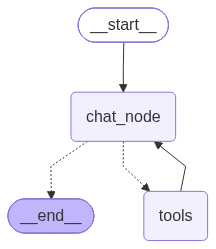

In [25]:
graph = StateGraph(ChatState)

graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)

graph.add_edge(START, "chat_node")
graph.add_conditional_edges("chat_node", tools_condition)
graph.add_edge("tools", "chat_node")

chatbot = graph.compile()
chatbot


## 19.8 Test the AI Agent

In [26]:
agent_question = input("Ask Shopper AI Agent a question: ")

result = chatbot.invoke({
    "messages": [HumanMessage(content=agent_question)]
})

print(result["messages"][-1].content)


The **Online Shoppers Purchasing Intention** dataset is a publicly‑available collection of e‑commerce browsing sessions that was originally compiled for a research paper on web‑mining and customer behavior.  

### Key facts  

| Aspect | Details |
|--------|---------|
| **Rows (sessions)** | **12,330** individual shopping sessions |
| **Columns (features)** | **18** variables describing each session |
| **Target variable** | **`Revenue`** – a Boolean flag (`True` = the visitor completed a purchase, `False` = no purchase) |
| **Typical features** | • `Administrative`, `Administrative_Duration` – counts and time on admin pages  <br>• `Informational`, `Informational_Duration` – counts and time on informational pages  <br>• `ProductRelated`, `ProductRelated_Duration` – counts and time on product pages  <br>• `BounceRates`, `ExitRates`, `PageValues` – site‑usage metrics  <br>• `SpecialDay` – closeness to a special event (e.g., holiday)  <br>• `Month`, `OperatingSystems`, `Browser`, `Region`

## 19.9 Try example questions

In [27]:
# Run one example at a time:
# result = chatbot.invoke({"messages": [HumanMessage(content="How many rows and columns are in my dataset?")]})
# print(result["messages"][-1].content)

# result = chatbot.invoke({"messages": [HumanMessage(content="What does the Revenue column mean?")]})
# print(result["messages"][-1].content)

# For prediction, provide feature values as JSON using the encoded column names from X.
# result = chatbot.invoke({"messages": [HumanMessage(content='Predict purchase using this session: {"Administrative": 0, "ProductRelated": 5}')]})
# print(result["messages"][-1].content)
